### Exporting data and data cleaning

In [69]:
#Importing libaries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
# 1.Importing input data from ("dosage_data_all)

df = pd.read_csv("dosage_data_all.csv")

df.head()

,Date,raw_ph,raw_ntu,initial_cl,month,dosage.Poly Used (kg)
0,26/07/01,7.38,3.66,2.0,July,216
1,26/07/02,8.00,3.57,2.0,July,252
2,26/07/03,7.31,4.08,3.6,July,216
3,26/07/04,7.09,3.92,2.2,July,252
4,26/07/05,7.19,4.31,2.2,July,216


In [71]:
df = df.rename(columns={"dosage.Poly Used (kg)":"dosage"})

df

,Date,raw_ph,raw_ntu,initial_cl,month,dosage
0,26/07/01,7.38,3.66,2.0,July,216
1,26/07/02,8.00,3.57,2.0,July,252
2,26/07/03,7.31,4.08,3.6,July,216
3,26/07/04,7.09,3.92,2.2,July,252
4,26/07/05,7.19,4.31,2.2,July,216
...,...,...,...,...,...,...
62,26/09/26,NaN,5.63,2.3,September,252
63,26/09/27,NaN,5.71,2.4,September,252
64,26/09/28,NaN,5.23,2.1,September,288
65,26/09/29,9.32,5.06,2.1,September,216


In [72]:
df.info

<bound method DataFrame.info of         Date  raw_ph  raw_ntu  initial_cl      month  dosage
0   26/07/01    7.38     3.66         2.0       July     216
1   26/07/02    8.00     3.57         2.0       July     252
2   26/07/03    7.31     4.08         3.6       July     216
3   26/07/04    7.09     3.92         2.2       July     252
4   26/07/05    7.19     4.31         2.2       July     216
..       ...     ...      ...         ...        ...     ...
62  26/09/26     NaN     5.63         2.3  September     252
63  26/09/27     NaN     5.71         2.4  September     252
64  26/09/28     NaN     5.23         2.1  September     288
65  26/09/29    9.32     5.06         2.1  September     216
66  26/09/30    8.34     6.34         2.1  September     276

[67 rows x 6 columns]>

In [73]:
df["dosage"] = round(df.dosage/12, 2)

df

,Date,raw_ph,raw_ntu,initial_cl,month,dosage
0,26/07/01,7.38,3.66,2.0,July,18.0
1,26/07/02,8.00,3.57,2.0,July,21.0
2,26/07/03,7.31,4.08,3.6,July,18.0
3,26/07/04,7.09,3.92,2.2,July,21.0
4,26/07/05,7.19,4.31,2.2,July,18.0
...,...,...,...,...,...,...
62,26/09/26,NaN,5.63,2.3,September,21.0
63,26/09/27,NaN,5.71,2.4,September,21.0
64,26/09/28,NaN,5.23,2.1,September,24.0
65,26/09/29,9.32,5.06,2.1,September,18.0


In [74]:
df = df.drop("Date", axis=1)

In [75]:
df = df.dropna()

In [76]:
df = df[df.raw_ph <8]

df

,raw_ph,raw_ntu,initial_cl,month,dosage
0,7.38,3.66,2.0,July,18.0
2,7.31,4.08,3.6,July,18.0
3,7.09,3.92,2.2,July,21.0
4,7.19,4.31,2.2,July,18.0
5,7.21,4.29,2.0,July,24.0
6,7.14,3.40,2.3,July,18.0
7,7.16,4.27,2.3,July,24.0
8,7.09,5.76,3.0,July,12.0
9,7.20,4.49,2.3,July,21.0
10,7.20,3.00,2.3,July,15.0


### EDA

## 1. Univariate Analysis(Individual Feature Profiles)
* Analyze each variable independentky to undsertsnad its central tendency,spread and distribution shape.
* Numerical Features (raw_ph,raw_ntu,initial_cl,dosage)
* Summary Statistics: Calculate mean,median,standard deviation,interquartile range,minimum and maximum values.
* Distribution Plots: Use histogram and kernel Density Estimation plots. Water quality parameters like turbidity(raw_ntu) and chemical dosages(dosage) are frequently right-skewed due to occassional storm events or high-load conditions.
* Boxplots: Excellent for quickly identifying potential outliers or extreme operational spikes(e.g> an unusually high initial turbidity reading)


In [77]:
print(df.columns.tolist())

['raw_ph', 'raw_ntu', 'initial_cl', 'month', 'dosage']


In [93]:
describe = df.describe()

describe.to_excel("descriptive analysis.xlsx")
describe

,raw_ph,raw_ntu,initial_cl,dosage
count,54.000000,54.000000,54.000000,54.000000
mean,7.275556,4.641852,2.262963,21.833333
std,0.153114,0.780977,0.477136,5.807445
min,7.000000,3.000000,1.300000,10.000000
25%,7.162500,4.162500,2.000000,18.000000
50%,7.245000,4.565000,2.200000,21.000000
75%,7.377500,5.165000,2.400000,26.000000
max,7.640000,6.410000,3.600000,33.000000


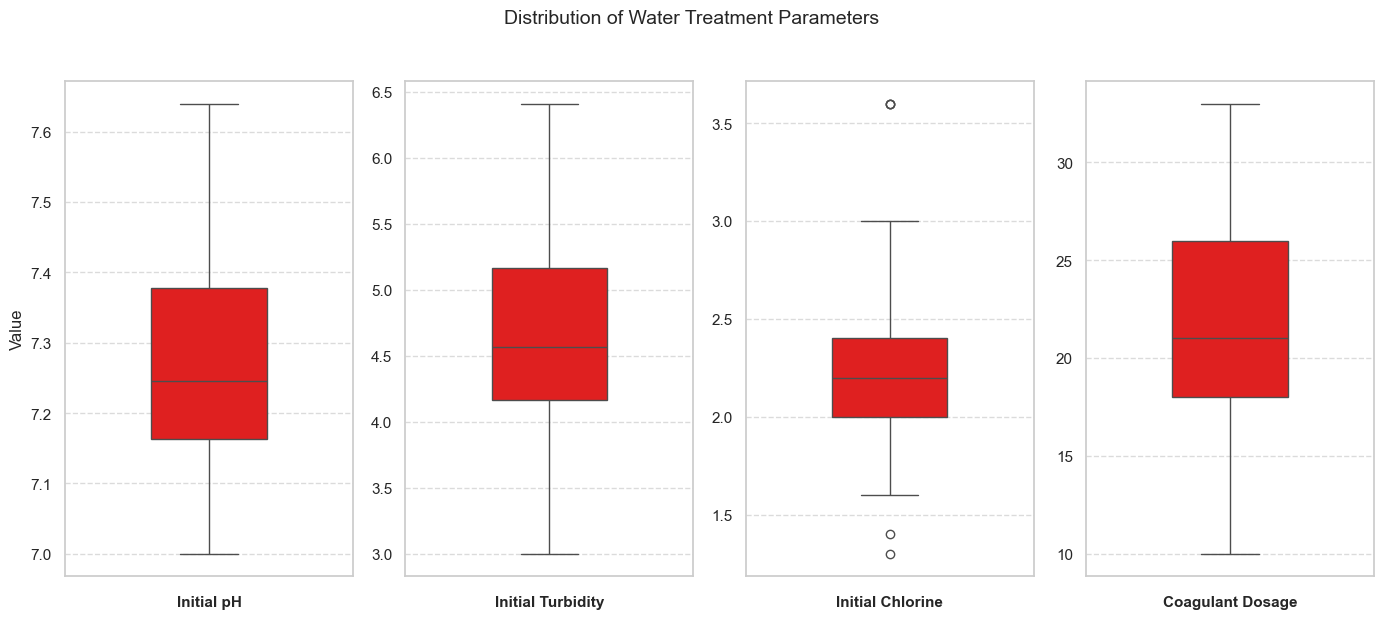

In [88]:
# 2.Define your custom labels mapping
feature_labels = {
    'raw_ph': 'Initial pH',
    'raw_ntu': 'Initial Turbidity',
    'initial_cl': 'Initial Chlorine',
    'dosage': 'Coagulant Dosage',
}

# 3.Create subplots (1 row, N columns)
fig, axes = plt.subplots(1, len(feature_labels), figsize=(14, 6))

# 4.Generate vertical boxplots for each feature
for ax, (col, label) in zip(axes, feature_labels.items()):
    sns.boxplot(y=df[col], ax=ax, color='red', width=0.4)

    # Label the x-axis with the custom name and clean up layout
    ax.set_xlabel(label, fontsize=11, fontweight='bold')
    ax.set_ylabel('Value' if col == 'raw_ph' else '')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Distribution of Water Treatment Parameters', fontsize=14, y=1.03)
plt.tight_layout()
plt.savefig("distribution graphs.png")
plt.show()

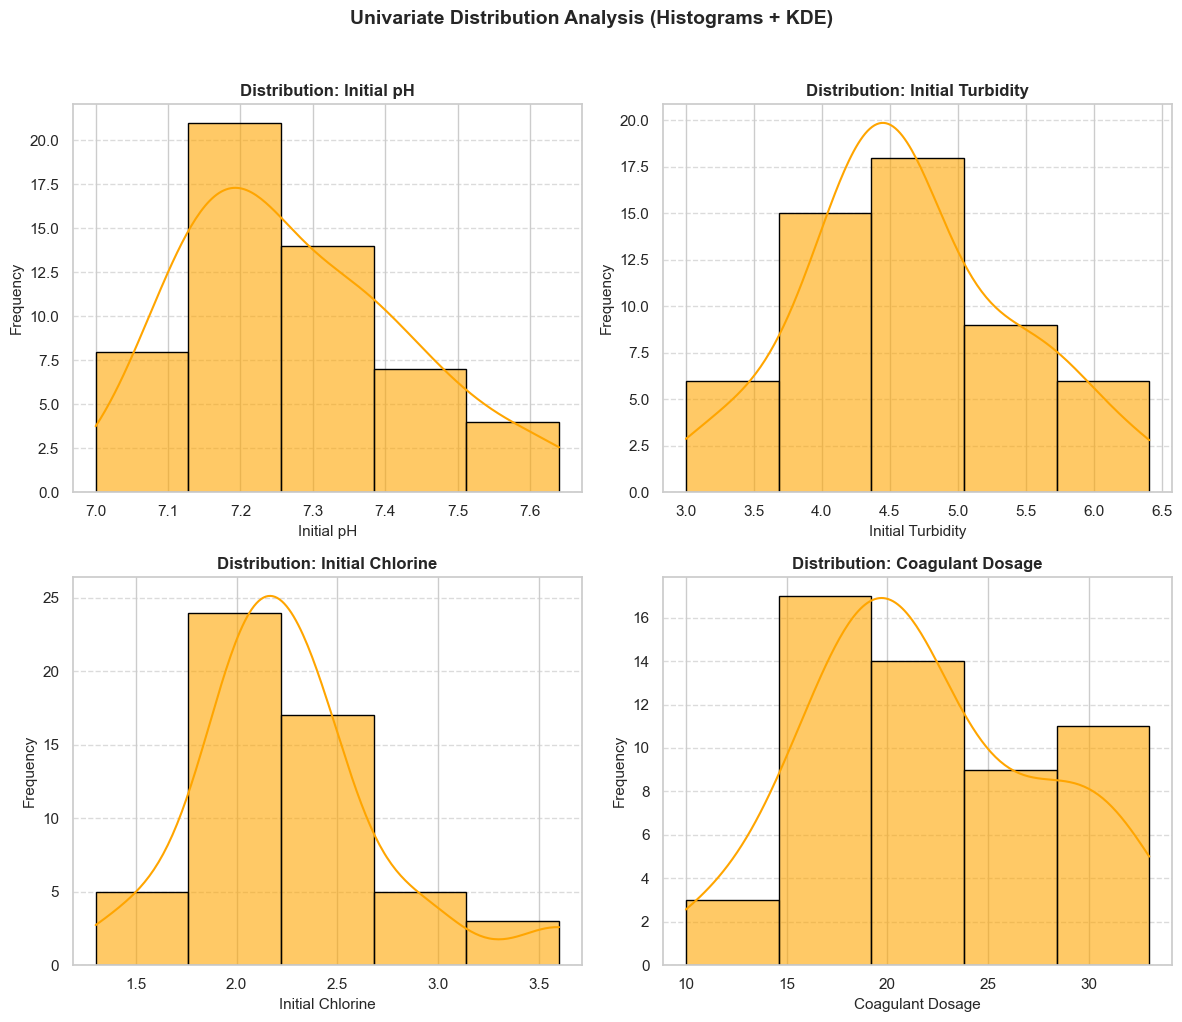

In [89]:
feature_labels = {
    'raw_ph': 'Initial pH',
    'raw_ntu': 'Initial Turbidity',
    'initial_cl': 'Initial Chlorine',
    'dosage': 'Coagulant Dosage'
}

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes = axes.flatten()

# Plot histograms and KDE curves
for ax, (col, label) in zip(axes, feature_labels.items()):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=ax,
        color='orange',
        bins=5,
        edgecolor='black',
        alpha=0.6
    )

    # Set titles and axis labels
    ax.set_title(
        f'Distribution: {label}',
        fontsize=12,
        fontweight='bold'
    )

    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('Frequency', fontsize=11)

    ax.grid(axis='y', linestyle='--', alpha=0.7)

# Main heading
plt.suptitle(
    'Univariate Distribution Analysis (Histograms + KDE)',
    fontsize=14,
    fontweight='bold',
    y=1.02
)

plt.tight_layout()
plt.savefig("univariate histo.png")
plt.show()

In [81]:
monthly_freq = df.groupby(df.month).count()["dosage"]

monthly_freq.sort_values(ascending=False)

month
August       22
July         21
September    11
Name: dosage, dtype: int64

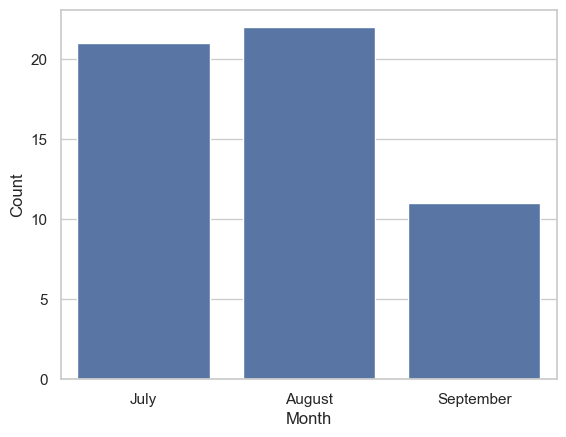

In [94]:
sns.barplot(monthly_freq.sort_values(), order = ["July", "August", "September"])
plt.xlabel("Month");
plt.ylabel("Count")
plt.savefig("month bar graphs.png")

## 2.Bivariate and Mulitivariate Analysis(Feature-Target Realtionships)

* Explore how individual predicators interact with each other and how strongly they influence the target variable(dosage).
* Correlation Analysis: Generate a correlation matrix heatmap(using Pearson for linear relationships and Spearman for monotonic/non-linear relationships).
* Domain Insight: Expect strong positive correlations between raw_ntu(turbidity) and dosage, as higher suspended solids typically require more coagulant.
* Scatter plots and Pairplots: Plot raw_ntu vs dosage and initial_cl vs dosage with regression or LOWESS(Locally Weighted Scatterplot Smoothing) curves to detect non-linear trends. ANN handles non-linear boundaries well, so spotting curves or clusters early is helpful.
* Multivariate Interactions: Create scatter plots with hue or color-coding by month or raw_ph to see if the relationship between turbidity and dosage changes under different baseline pH conditions.

In [83]:
corr_matrix = df.select_dtypes(include = "number").corr()

corr_matrix

,raw_ph,raw_ntu,initial_cl,dosage
raw_ph,1.000000,0.211078,-0.059631,0.003819
raw_ntu,0.211078,1.000000,-0.115613,0.149374
initial_cl,-0.059631,-0.115613,1.000000,-0.154796
dosage,0.003819,0.149374,-0.154796,1.000000


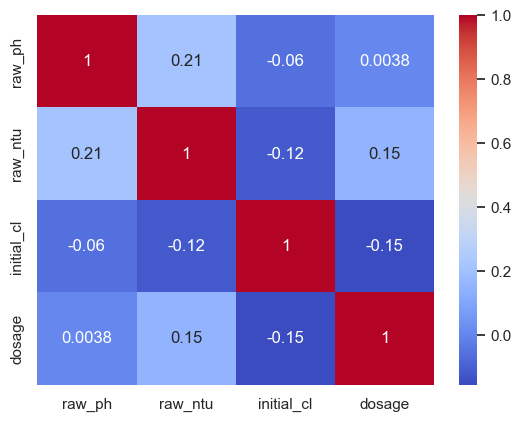

In [84]:
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm");
plt.savefig("heatmap.png")

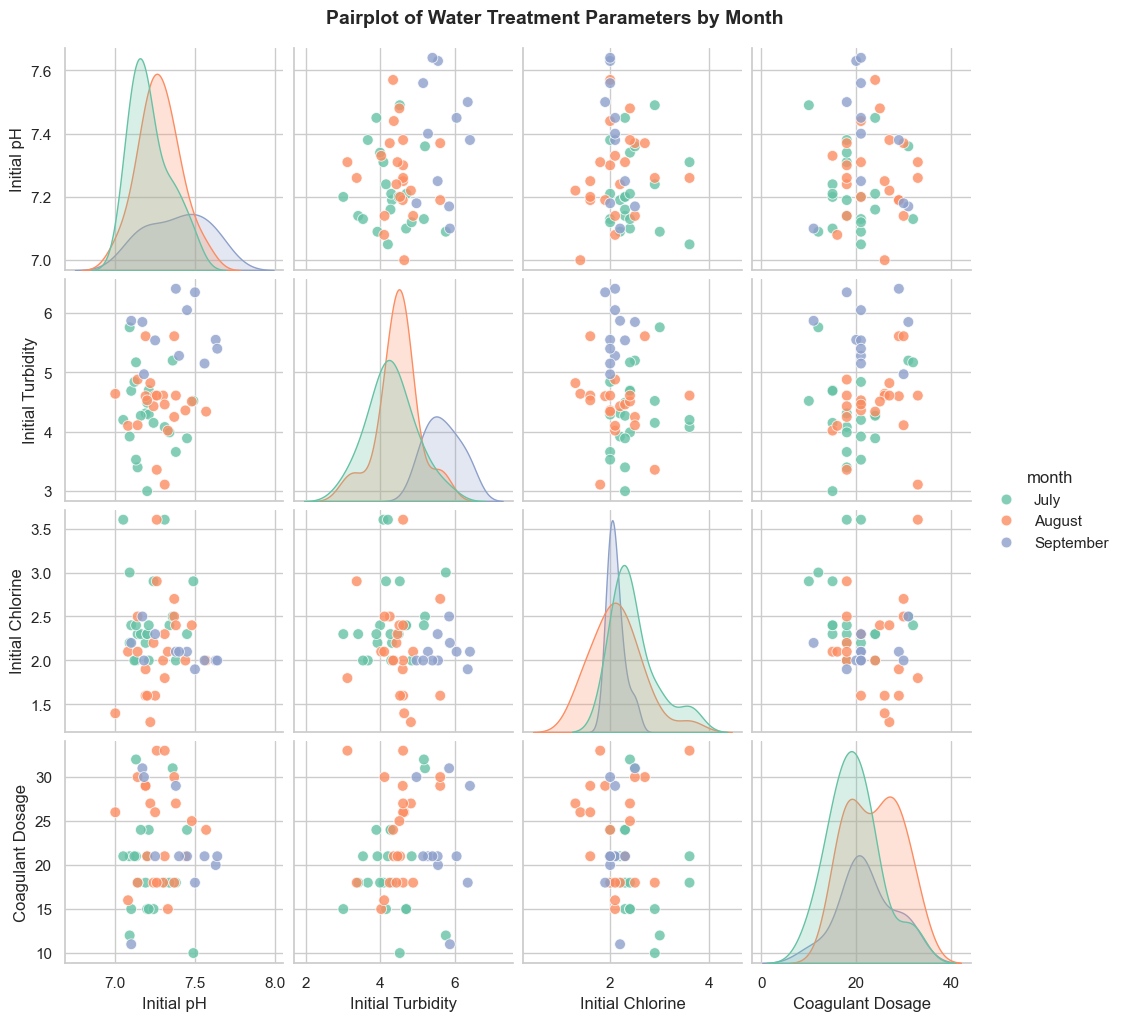

In [90]:
feature_labels = {
    'raw_ph': 'Initial pH',
    'raw_ntu': 'Initial Turbidity',
    'initial_cl': 'Initial Chlorine',
    'dosage': 'Coagulant Dosage',
}

df_plot = df.rename(columns=feature_labels)

# 3. Generate the pairplot
# 'diag_kind="kde"' shows kernel density estimates on the diagonal instead of histograms
g = sns.pairplot(
    df_plot,
    hue='month',
    diag_kind='kde',
    palette='Set2',
    plot_kws={'alpha': 0.8, 's': 60},
)

# 4. Add a title to the entire figure
g.fig.suptitle(
    'Pairplot of Water Treatment Parameters by Month',
    y=1.02,
    fontsize=14,
    fontweight='bold',
)

plt.savefig("PAIRPLOT.png")
plt.show()

## 3.Temporal and Seasonal EDA(Leveraging the month variable)
1. Coagulation demand is highly seasonal(e.g. rainy seasons vs dry seasons affecting raw water quality).
2. Aggregated Monthly Trends:
* Calculate the average, median, and maximum dosage, raw_ntu and raw_ph grouped by month.
* Use boxplots or violin plots of dosage grouped by month to visualize seasonal shifts in coagulant demand.
3. Cyclical Pattern Check:
* Since months form a continous cycle(January to December), visualize whether transations between months show smooth seasonal drift in water characteristics.

C:\Users\mstsh\AppData\Local\Temp\ipykernel_13112\3075776048.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


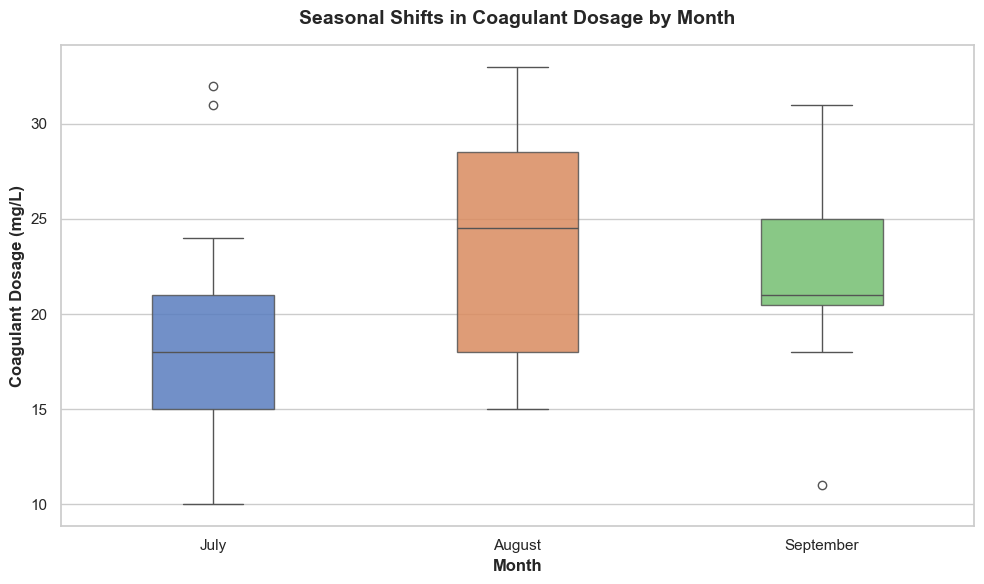

In [91]:
# 2. Set up the plotting environment
plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

# 3. Create the grouped box plot
sns.boxplot(
    data=df,
    x='month',
    y='dosage',
    order=[
        'July',
        'August',
        "September"
    ],  # Optional: enforce chronological ordering if needed
    palette='muted',
    width=0.4,
    boxprops=dict(alpha=0.85),
)

# 4. Customize titles and labels
plt.title(
    'Seasonal Shifts in Coagulant Dosage by Month',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Month', fontsize=12, fontweight='bold')
plt.ylabel('Coagulant Dosage (mg/L)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig("boxplot.png")
plt.show()